# CODSOFT TASK 2 — EXPLORATORY DATA ANALYSIS (EDA)

**Dataset:** IPL cricket matches (`matches.csv`)  
**Tools:** Python, Pandas, Matplotlib and Seaborn  
**Dataset size:** 636 match records and 18 columns (as inspected when preparing this notebook).

## Objectives
1. Examine the dataset using descriptive statistics.
2. Identify trends, distributions and relationships between variables.
3. Detect outliers and unusual patterns.
4. Answer cricket/business questions using summary statistics.
5. **Bonus:** Generate a short findings report.

> Keep `matches.csv` in the same folder as this notebook. This notebook analyzes the supplied dataset; it does not represent all IPL seasons or all IPL matches.

## 1. Import required libraries

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


## 2. Load the cricket dataset

In [26]:
CSV_FILE = "matches.csv"

if not Path(CSV_FILE).exists():
    raise FileNotFoundError(
        "matches.csv was not found. Keep it in the same folder as this notebook."
    )

raw_data = pd.read_csv(CSV_FILE)
print("Dataset shape:", raw_data.shape)
display(raw_data.head())

FileNotFoundError: matches.csv was not found. Keep it in the same folder as this notebook.

## 3. Inspect dataset structure

In [27]:
print("Column names:")
print(raw_data.columns.tolist())

print("\nData types and non-null counts:")
raw_data.info()

print("\nDescriptive statistics — numeric columns:")
display(raw_data.describe())

print("\nDescriptive statistics — categorical columns:")
display(raw_data.describe(include="object").T)

Column names:
['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner', 'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2', 'umpire3']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               636 non-null    int64  
 1   season           636 non-null    int64  
 2   city             629 non-null    str    
 3   date             636 non-null    str    
 4   team1            636 non-null    str    
 5   team2            636 non-null    str    
 6   toss_winner      636 non-null    str    
 7   toss_decision    636 non-null    str    
 8   result           636 non-null    str    
 9   dl_applied       636 non-null    int64  
 10  winner           633 non-null    str    
 11  win_by_runs      636 non-null    int64  
 12 

,id,season,dl_applied,win_by_runs,win_by_wickets,umpire3
count,636.000000,636.000000,636.000000,636.000000,636.000000,0.0
mean,318.500000,2012.490566,0.025157,13.682390,3.372642,NaN
std,183.741666,2.773026,0.156726,23.908877,3.420338,NaN
min,1.000000,2008.000000,0.000000,0.000000,0.000000,NaN
25%,159.750000,2010.000000,0.000000,0.000000,0.000000,NaN
50%,318.500000,2012.000000,0.000000,0.000000,4.000000,NaN
75%,477.250000,2015.000000,0.000000,20.000000,7.000000,NaN
max,636.000000,2017.000000,1.000000,146.000000,10.000000,NaN



Descriptive statistics — categorical columns:


C:\Users\matiu\AppData\Local\Temp\ipykernel_15752\2756008372.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(raw_data.describe(include="object").T)


,count,unique,top,freq
city,629,30,Mumbai,85
date,636,450,2017-04-08,2
team1,636,14,Mumbai Indians,82
team2,636,14,Delhi Daredevils,84
toss_winner,636,14,Mumbai Indians,85
toss_decision,636,2,field,363
result,636,3,normal,626
winner,633,14,Mumbai Indians,92
player_of_match,633,201,CH Gayle,18
venue,636,35,M Chinnaswamy Stadium,66


## 4. Missing values and duplicate records

In [28]:
missing_summary = raw_data.isna().sum().to_frame("missing_values")
missing_summary["missing_percent"] = (missing_summary["missing_values"] / len(raw_data) * 100).round(2)
display(missing_summary.sort_values("missing_values", ascending=False))

print("Duplicate rows:", raw_data.duplicated().sum())
print("Completely empty columns:", raw_data.columns[raw_data.isna().all()].tolist())

,missing_values,missing_percent
umpire3,636,100.00
city,7,1.10
winner,3,0.47
player_of_match,3,0.47
umpire1,1,0.16
umpire2,1,0.16
season,0,0.00
id,0,0.00
team1,0,0.00
date,0,0.00


Duplicate rows: 0
Completely empty columns: ['umpire3']


## 5. Prepare data for analysis

In [29]:
data = raw_data.copy()
data.columns = data.columns.str.strip().str.lower()

# Convert date column to datetime
data["date"] = pd.to_datetime(data["date"], errors="coerce")

# Remove exact duplicate rows, if any
data = data.drop_duplicates().copy()

# Remove columns that contain no information in this dataset
empty_columns = data.columns[data.isna().all()].tolist()
data = data.drop(columns=empty_columns)

# Add year/month fields for trend analysis
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month

print("Prepared dataset shape:", data.shape)
print("Columns removed because they were completely empty:", empty_columns)
display(data.head())

Prepared dataset shape: (636, 19)
Columns removed because they were completely empty: ['umpire3']


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,year,month
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,2017,4
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,2017,4
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,2017,4
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,2017,4
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,2017,4


## 6. Univariate analysis — distributions

### 6.1 Matches by season

,matches
season,
2008,58
2009,57
2010,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


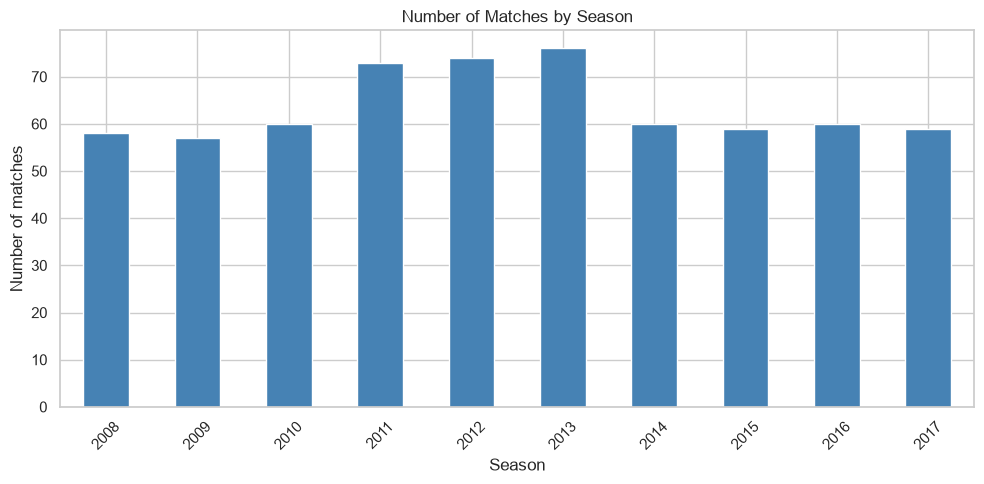

In [30]:
season_counts = data["season"].value_counts().sort_index()
display(season_counts.to_frame("matches"))

season_counts.plot(kind="bar", color="steelblue", title="Number of Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.2 Toss decision distribution

,matches
toss_decision,
field,363
bat,273


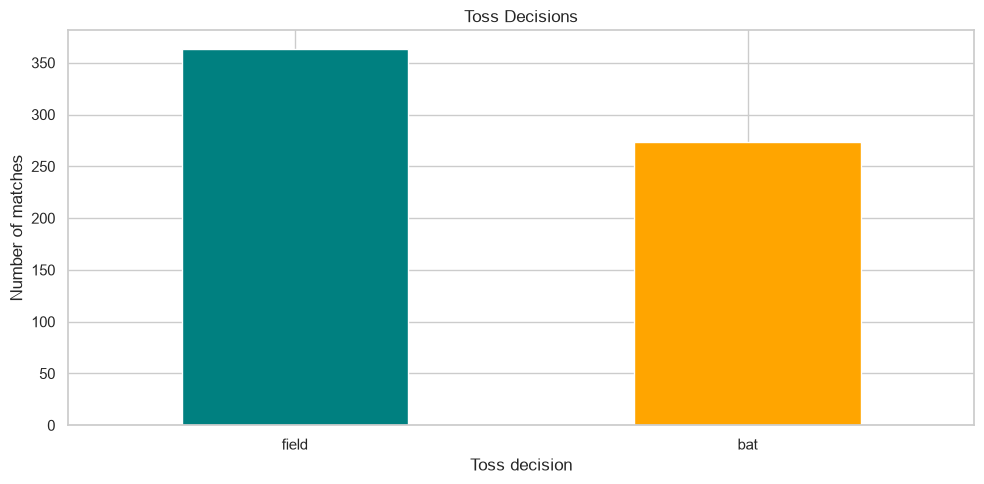

In [31]:
toss_counts = data["toss_decision"].value_counts()
display(toss_counts.to_frame("matches"))

toss_counts.plot(kind="bar", color=["teal", "orange"], title="Toss Decisions")
plt.xlabel("Toss decision")
plt.ylabel("Number of matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.3 Distribution of victory margins

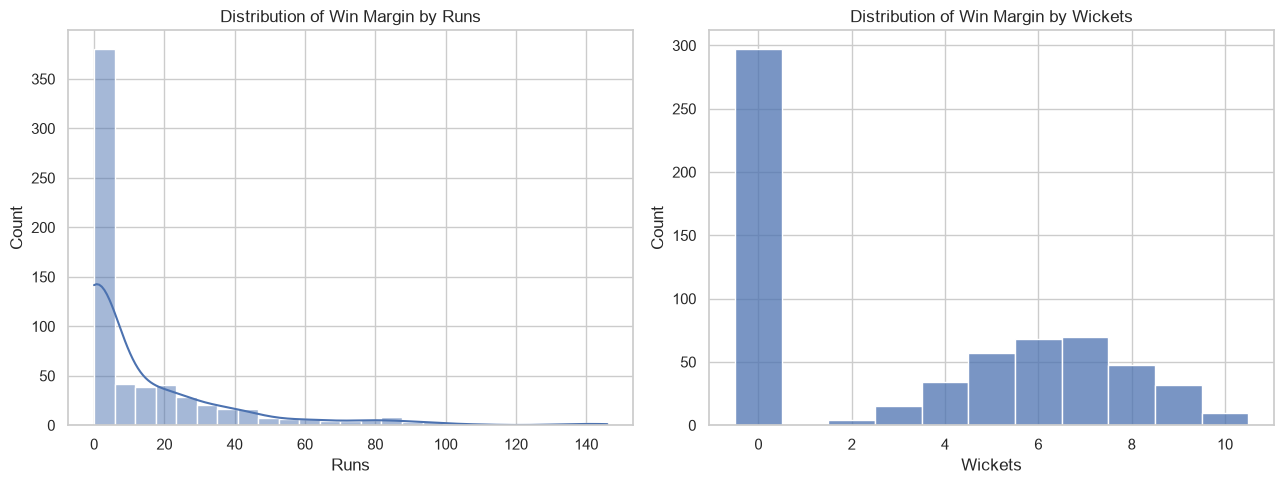

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=data, x="win_by_runs", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Win Margin by Runs")
axes[0].set_xlabel("Runs")

sns.histplot(data=data, x="win_by_wickets", bins=11, discrete=True, ax=axes[1])
axes[1].set_title("Distribution of Win Margin by Wickets")
axes[1].set_xlabel("Wickets")

plt.tight_layout()
plt.show()

## 7. Bivariate analysis — relationships

### 7.1 Does winning the toss relate to winning the match?

In [33]:
toss_match = data.dropna(subset=["toss_winner", "winner"]).copy()
toss_match["toss_and_match_winner"] = toss_match["toss_winner"] == toss_match["winner"]
toss_success = toss_match["toss_and_match_winner"].value_counts().rename(
    index={True: "Toss winner also won match", False: "Toss winner lost match"}
)
display(toss_success.to_frame("matches"))
print("Toss-to-match win percentage:",
      round(toss_match["toss_and_match_winner"].mean() * 100, 2), "%")

,matches
toss_and_match_winner,
Toss winner also won match,325
Toss winner lost match,308


Toss-to-match win percentage: 51.34 %


### 7.2 Toss decision versus match outcome

,matches,toss_winner_match_wins,success_rate
toss_decision,,,
bat,272,124,45.59
field,361,201,55.68


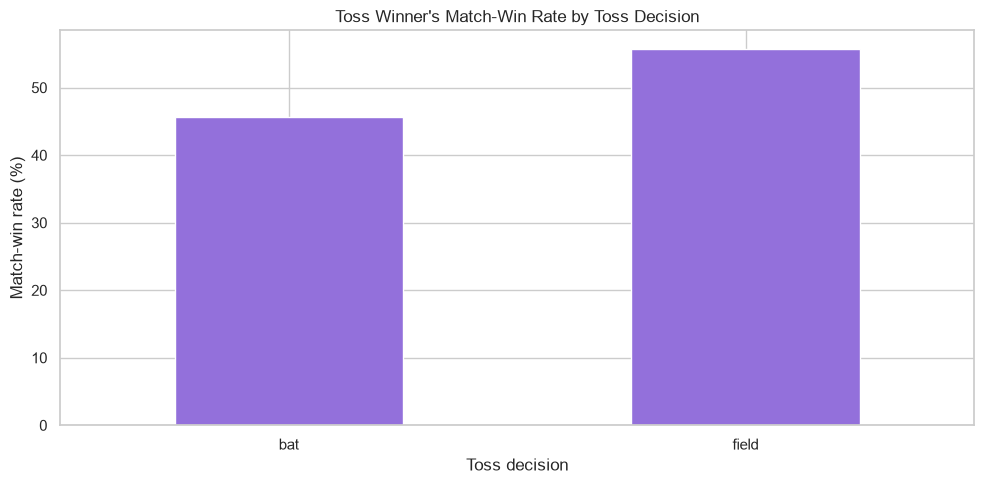

In [34]:
decision_success = (toss_match.groupby("toss_decision")["toss_and_match_winner"]
                   .agg(matches="count", toss_winner_match_wins="sum", success_rate="mean"))
decision_success["success_rate"] = (decision_success["success_rate"] * 100).round(2)
display(decision_success)

decision_success["success_rate"].plot(kind="bar", color="mediumpurple",
                                      title="Toss Winner's Match-Win Rate by Toss Decision")
plt.xlabel("Toss decision")
plt.ylabel("Match-win rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.3 Most successful teams in this dataset

,matches_won
winner,
Mumbai Indians,92
Chennai Super Kings,79
Kolkata Knight Riders,77
Royal Challengers Bangalore,73
Kings XI Punjab,70
Rajasthan Royals,63
Delhi Daredevils,62
Sunrisers Hyderabad,42
Deccan Chargers,29


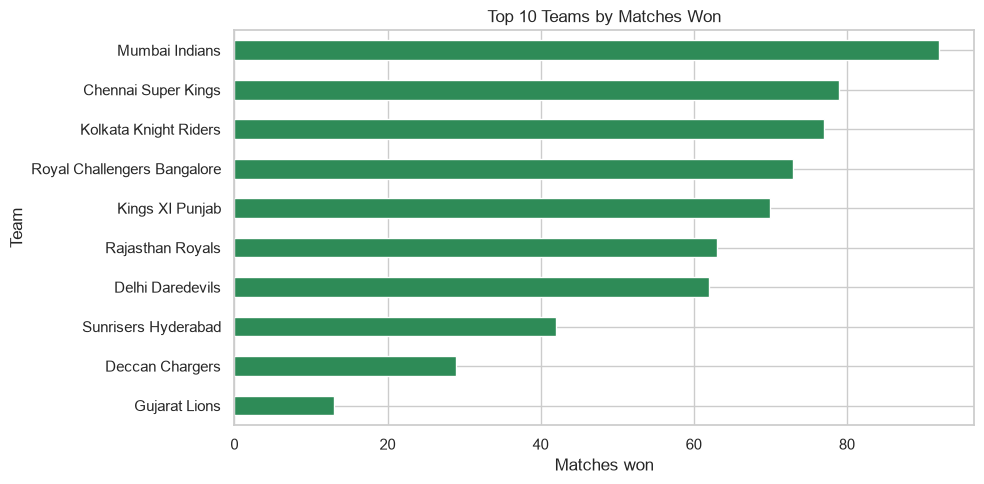

In [35]:
team_wins = data["winner"].value_counts().head(10)
display(team_wins.to_frame("matches_won"))

team_wins.sort_values().plot(kind="barh", color="seagreen",
                             title="Top 10 Teams by Matches Won")
plt.xlabel("Matches won")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

### 7.4 Most common venues

In [ ]:
venue_counts = data["venue"].value_counts().head(10)
display(venue_counts.to_frame("matches_hosted"))

venue_counts.sort_values().plot(kind="barh", color="coral",
                                title="Top 10 Venues by Matches in Dataset")
plt.xlabel("Number of matches")
plt.ylabel("Venue")
plt.tight_layout()
plt.show()

,matches_hosted
venue,
M Chinnaswamy Stadium,66
Eden Gardens,61
Feroz Shah Kotla,60
Wankhede Stadium,57
"Rajiv Gandhi International Stadium, Uppal",49
"MA Chidambaram Stadium, Chepauk",48
"Punjab Cricket Association Stadium, Mohali",35
Sawai Mansingh Stadium,33
Dr DY Patil Sports Academy,17


## 8. Correlation analysis

,id,season,dl_applied,win_by_runs,win_by_wickets,year,month
id,1.00,0.47,0.02,-0.01,-0.02,0.47,0.17
season,0.47,1.00,0.00,-0.02,-0.00,1.00,0.05
dl_applied,0.02,0.00,1.00,-0.01,-0.01,0.00,0.07
win_by_runs,-0.01,-0.02,-0.01,1.00,-0.57,-0.02,-0.02
win_by_wickets,-0.02,-0.00,-0.01,-0.57,1.00,-0.00,-0.00
year,0.47,1.00,0.00,-0.02,-0.00,1.00,0.05
month,0.17,0.05,0.07,-0.02,-0.00,0.05,1.00


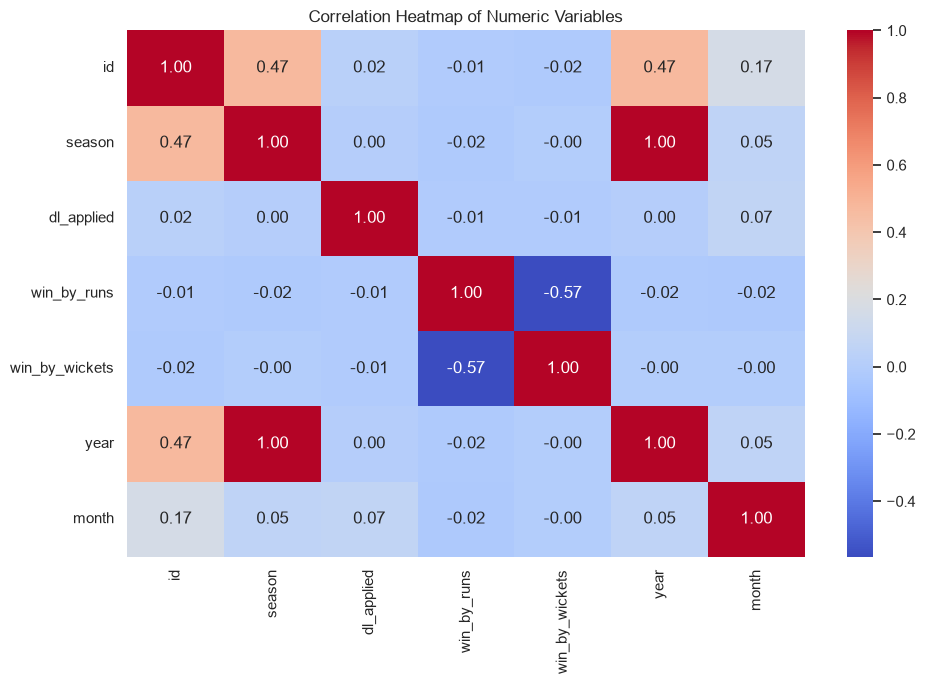

In [13]:
numeric_data = data.select_dtypes(include="number")
correlation = numeric_data.corr(numeric_only=True)
display(correlation.round(2))

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", square=False)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

## 9. Outlier detection using IQR

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
win_by_runs,0.0,20.0,20.0,-30.0,50.0,47.0
win_by_wickets,0.0,7.0,7.0,-10.5,17.5,0.0


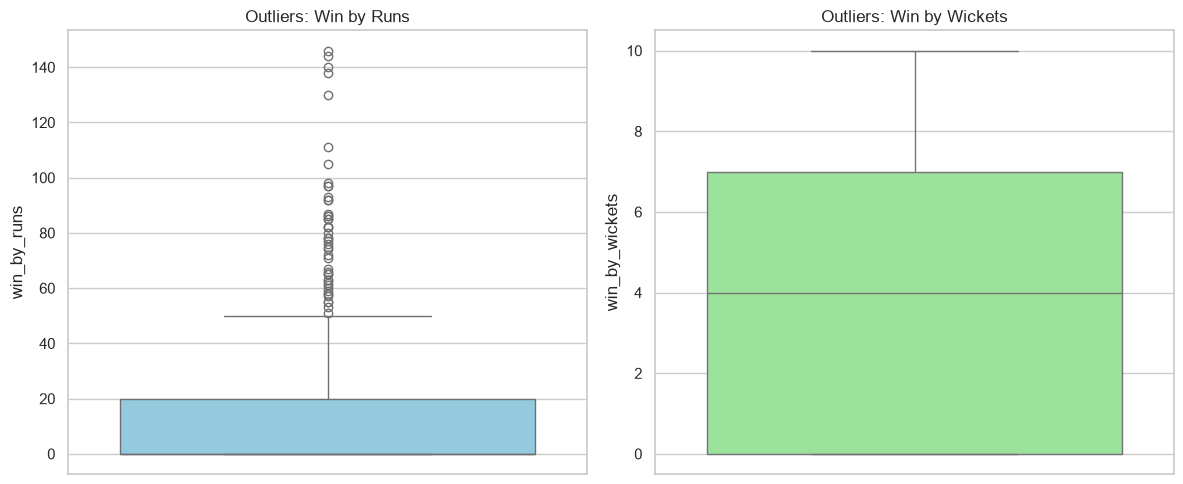

Note: A statistical outlier is not automatically an error; a very large victory margin may be a genuine match result.


In [14]:
def iqr_outlier_summary(series):
    values = series.dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = values[(values < lower) | (values > upper)]
    return {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "outlier_count": len(outliers)
    }

outlier_results = pd.DataFrame({
    "win_by_runs": iqr_outlier_summary(data["win_by_runs"]),
    "win_by_wickets": iqr_outlier_summary(data["win_by_wickets"])
}).T
display(outlier_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=data["win_by_runs"], ax=axes[0], color="skyblue")
axes[0].set_title("Outliers: Win by Runs")
sns.boxplot(y=data["win_by_wickets"], ax=axes[1], color="lightgreen")
axes[1].set_title("Outliers: Win by Wickets")
plt.tight_layout()
plt.show()

print("Note: A statistical outlier is not automatically an error; a very large victory margin may be a genuine match result.")

## 10. Business questions answered with summary statistics

In [15]:
# 1. Which season has the most matches?
matches_by_season = data["season"].value_counts()
top_season = int(matches_by_season.idxmax())
top_season_count = int(matches_by_season.max())

# 2. Which team has the most wins?
wins_by_team = data["winner"].value_counts()
top_team = wins_by_team.index[0]
top_team_wins = int(wins_by_team.iloc[0])

# 3. Which toss decision is most common?
common_toss_decision = data["toss_decision"].mode().iloc[0]
common_toss_count = int(data["toss_decision"].value_counts().max())

# 4. Which player received the most Player of the Match awards?
pom_counts = data["player_of_match"].value_counts()
top_player = pom_counts.index[0]
top_player_awards = int(pom_counts.iloc[0])

# 5. Which venue hosted the most matches?
top_venue = data["venue"].value_counts().index[0]
top_venue_matches = int(data["venue"].value_counts().iloc[0])

answers = pd.DataFrame({
    "Question": [
        "Season with the most matches",
        "Team with the most wins",
        "Most common toss decision",
        "Most Player of the Match awards",
        "Venue with the most matches"
    ],
    "Answer": [
        f"{top_season} ({top_season_count} matches)",
        f"{top_team} ({top_team_wins} wins)",
        f"{common_toss_decision} ({common_toss_count} matches)",
        f"{top_player} ({top_player_awards} awards)",
        f"{top_venue} ({top_venue_matches} matches)"
    ]
})
display(answers)

,Question,Answer
0,Season with the most matches,2013 (76 matches)
1,Team with the most wins,Mumbai Indians (92 wins)
2,Most common toss decision,field (363 matches)
3,Most Player of the Match awards,CH Gayle (18 awards)
4,Venue with the most matches,M Chinnaswamy Stadium (66 matches)


## 11. Key findings and conclusion

In [16]:
toss_win_rate = round(toss_match["toss_and_match_winner"].mean() * 100, 2)
total_matches = len(data)

findings = [
    f"The analyzed dataset contains {total_matches} match records.",
    f"Season {top_season} has the highest number of matches in this dataset ({top_season_count}).",
    f"{top_team} has the highest number of match wins in this dataset ({top_team_wins}).",
    f"The most common toss decision is '{common_toss_decision}'.",
    f"Toss winners also won {toss_win_rate}% of matches where both toss winner and match winner were recorded.",
    f"The venue with the most matches is {top_venue} ({top_venue_matches} matches)."
]
for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

print("\nConclusion:")
print("EDA summarizes match patterns, toss decisions, team performance, venues and victory margins.")
print("These findings describe only the records present in this supplied dataset; they should not be generalized to every IPL season.")

1. The analyzed dataset contains 636 match records.
2. Season 2013 has the highest number of matches in this dataset (76).
3. Mumbai Indians has the highest number of match wins in this dataset (92).
4. The most common toss decision is 'field'.
5. Toss winners also won 51.34% of matches where both toss winner and match winner were recorded.
6. The venue with the most matches is M Chinnaswamy Stadium (66 matches).

Conclusion:
EDA summarizes match patterns, toss decisions, team performance, venues and victory margins.
These findings describe only the records present in this supplied dataset; they should not be generalized to every IPL season.


## 12. Bonus — save a short EDA report

In [17]:
report_lines = [
    "CODSOFT TASK 2: EXPLORATORY DATA ANALYSIS REPORT",
    "",
    f"Records analyzed: {total_matches}",
    f"Season with most matches: {top_season} ({top_season_count})",
    f"Team with most wins: {top_team} ({top_team_wins})",
    f"Most common toss decision: {common_toss_decision}",
    f"Most Player of the Match awards: {top_player} ({top_player_awards})",
    f"Venue with most matches: {top_venue} ({top_venue_matches})",
    f"Toss winner also won the match in {toss_win_rate}% of eligible records.",
    "",
    "Methods used: descriptive statistics, distribution plots, group summaries, correlation heatmap and IQR-based outlier detection.",
    "Limitation: conclusions apply only to the supplied dataset and its covered seasons."
]
Path("Task2_EDA_Short_Report.txt").write_text("\n".join(report_lines), encoding="utf-8")
print("Saved: Task2_EDA_Short_Report.txt")
print("\n".join(report_lines))

Saved: Task2_EDA_Short_Report.txt
CODSOFT TASK 2: EXPLORATORY DATA ANALYSIS REPORT

Records analyzed: 636
Season with most matches: 2013 (76)
Team with most wins: Mumbai Indians (92)
Most common toss decision: field
Most Player of the Match awards: CH Gayle (18)
Venue with most matches: M Chinnaswamy Stadium (66)
Toss winner also won the match in 51.34% of eligible records.

Methods used: descriptive statistics, distribution plots, group summaries, correlation heatmap and IQR-based outlier detection.
Limitation: conclusions apply only to the supplied dataset and its covered seasons.


## 13. Export useful analysis tables
The following CSV files are created when this cell is run.

In [18]:
season_counts.rename_axis("season").to_frame("matches").to_csv("matches_by_season.csv")
team_wins.rename_axis("team").to_frame("wins").to_csv("team_wins_summary.csv")
answers.to_csv("eda_business_questions.csv", index=False)
print("Exported: matches_by_season.csv, team_wins_summary.csv, eda_business_questions.csv")

Exported: matches_by_season.csv, team_wins_summary.csv, eda_business_questions.csv
